# Phase 3 (Track 2) — Custom TensorFlow / Keras Convolutional Neural Network for Hubble Sequence Classification

This notebook documents **Classifier Track 2**, built completely from scratch using **TensorFlow / Keras** inside its own separate folder: `classifiers/tensorflow_cnn/`.

## Architecture Design (Extending the TensorFlow CNN Tutorial for Astrophysics)
Following the official TensorFlow Convolutional Neural Network design (`Conv2D` + `MaxPooling2D` + `Dense`), we tailor the network specifically for SDSS galaxy imaging:
1. **Astronomical Spatial-Invariance Augmentation**: Galaxies have no preferred orientation on the sky, so the input layer applies random horizontal/vertical flips and full **360° random rotations** (`RandomFlip`, `RandomRotation(0.5)`) during training.
2. **4-Block Convolutional Backbone**: Progressive `Conv2D` filters (`32 -> 64 -> 96 -> 128`) with `BatchNormalization`, `ReLU`, `MaxPooling2D`, and spatial `Dropout(0.25)`.
3. **Compact Classification Head**: `GlobalAveragePooling2D` -> `Dense(128, relu)` -> `Dropout(0.40)` -> `Dense(5, softmax)` over the **5 Hubble Sequence categories**:
   - `Elliptical`
   - `Lenticular/Edge-on`
   - `Tight Spiral (Sa)`
   - `Medium Spiral (Sb)`
   - `Loose Spiral / Irregular (Sc/Irr)`
4. **Class-Weighted Loss & Callbacks**: Inverse-frequency class weights counter natural astronomical class imbalance, paired with `EarlyStopping` and `ReduceLROnPlateau`.

In [1]:
import json
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

from classifiers.tensorflow_cnn.cnn_model import build_hubble_cnn
from classifiers.tensorflow_cnn.hubble_taxonomy import HUBBLE_CLASSES
from classifiers.tensorflow_cnn.train_and_predict import TensorFlowHubbleTrainer
from src.config import ProjectConfig
from src.database import GalaxyDatabase

config = ProjectConfig()
ARTIFACTS_DIR = PROJECT_ROOT / "classifiers" / "tensorflow_cnn" / "artifacts"
RUN_TRAINING = False  # Set True to re-train the custom TensorFlow CNN from scratch

model = build_hubble_cnn(input_shape=(69, 69, 3), num_classes=len(HUBBLE_CLASSES))
model.summary()

Model: "TensorFlow_Hubble_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ astro_random_flip             │ (None, 69, 69, 3)     │            0 │
│ (RandomFlip)                  │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ astro_random_rot360           │ (None, 69, 69, 3)     │            0 │
│ (RandomRotation)              │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv_block1_a (Conv2D)        │ (None, 69, 69, 32)    │          864 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ bn_block1_a                   │ (None, 69, 69, 32)    │          128 │
│ (BatchNormalization)          │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ relu_block1_a (ReLU)          │ (None, 69, 69, 32)    │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ pool_block1 (MaxPooling2D)    │ (None, 34, 34, 32)    │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv_block2_a (Conv2D)        │ (None, 34, 34, 64)    │       18,432 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ bn_block2_a                   │ (None, 34, 34, 64)    │          256 │
│ (BatchNormalization)          │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ relu_block2_a (ReLU)          │ (None, 34, 34, 64)    │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ pool_block2 (MaxPooling2D)    │ (None, 17, 17, 64)    │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv_block3_a (Conv2D)        │ (None, 17, 17, 96)    │       55,296 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ bn_block3_a                   │ (None, 17, 17, 96)    │          384 │
│ (BatchNormalization)          │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ relu_block3_a (ReLU)          │ (None, 17, 17, 96)    │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ pool_block3 (MaxPooling2D)    │ (None, 8, 8, 96)      │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dropout_conv (Dropout)        │ (None, 8, 8, 96)      │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv_block4_a (Conv2D)        │ (None, 8, 8, 128)     │      110,592 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ bn_block4_a                   │ (None, 8, 8, 128)     │          512 │
│ (BatchNormalization)          │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ relu_block4_a (ReLU)          │ (None, 8, 8, 128)     │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ global_avg_pool               │ (None, 128)           │            0 │
│ (GlobalAveragePooling2D)      │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_features (Dense)        │ (None, 128)           │       16,512 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dropout_head (Dropout)        │ (None, 128)           │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ hubble_probs (Dense)          │ (None, 5)             │          645 │
└───────────────────────────────┴───────────────────────┴──────────────┘

 Total params: 203,621 (795.39 KB)

 Trainable params: 202,981 (792.89 KB)

 Non-trainable params: 640 (2.50 KB)

---
## Step 1: Train (or Load) Evaluation Metrics, Learning Curves & Confusion Matrix

Custom TensorFlow CNN Test Accuracy: 0.7667 | Macro F1: 0.5181
Trainable parameters: 203,621 | Epochs run: 12


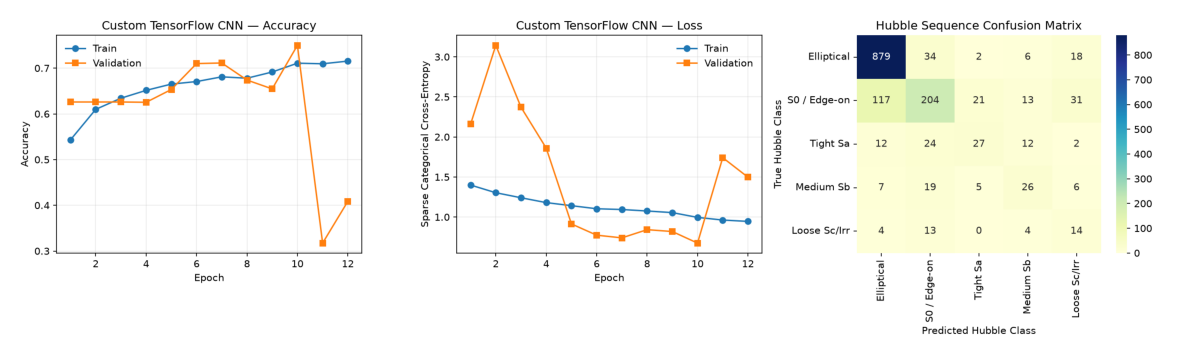

In [2]:
metrics_path = ARTIFACTS_DIR / "tf_cnn_metrics.json"

if RUN_TRAINING or not metrics_path.exists():
    trainer = TensorFlowHubbleTrainer(config)
    tf_metrics = trainer.train_and_evaluate(epochs=12, max_samples=10000)
    with GalaxyDatabase(config.db_path) as db:
        n_pred = trainer.predict_catalog_cutouts(db)
        tf_metrics["n_catalog_predicted"] = n_pred
else:
    tf_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))

print(f"Custom TensorFlow CNN Test Accuracy: {tf_metrics['test_accuracy']:.4f} | Macro F1: {tf_metrics['macro_f1']:.4f}")
print(f"Trainable parameters: {tf_metrics['n_parameters']:,} | Epochs run: {tf_metrics['epochs_run']}")

eval_fig = config.figures_dir / "tf_cnn_evaluation.png"
if eval_fig.exists():
    plt.figure(figsize=(15, 4.6))
    plt.imshow(Image.open(eval_fig))
    plt.axis("off")
    plt.show()

---
## Step 2: Independent Astrophysical Cross-Validation on Our SDSS DR17 Catalog

A powerful sanity check in computational astrophysics is verifying whether the CNN's purely visual Hubble classifications recover real physical trends in independent catalog measurements (`concentration`, `color_gr`, `log_sfr`, and Galaxy Zoo votes)!

In [3]:
with GalaxyDatabase(config.db_path) as db:
    hubble_phys = db.query_df(
        """
        SELECT
            p.predicted_class AS hubble_class,
            COUNT(*) AS n_galaxies,
            ROUND(AVG(p.confidence), 3) AS avg_confidence,
            ROUND(AVG(g.concentration), 3) AS avg_concentration,
            ROUND(AVG(g.color_gr), 3) AS avg_color_gr,
            ROUND(AVG(g.log_stellar_mass), 3) AS avg_log_mass,
            ROUND(AVG(g.log_sfr), 3) AS avg_log_sfr,
            ROUND(AVG(g.p_el_debiased), 3) AS avg_zoo_el,
            ROUND(AVG(g.p_cs_debiased), 3) AS avg_zoo_spiral
        FROM predictions AS p
        INNER JOIN galaxies AS g ON g.objID = p.objID
        WHERE p.model_name = 'tensorflow_hubble_cnn'
        GROUP BY p.predicted_class
        ORDER BY avg_concentration DESC
        """
    )

display(hubble_phys)

,hubble_class,n_galaxies,avg_confidence,avg_concentration,avg_color_gr,avg_log_mass,avg_log_sfr,avg_zoo_el,avg_zoo_spiral
0,Lenticular/Edge-on,43,0.651,2.859,0.924,10.701,-0.726,0.636,0.350
1,Elliptical,19,0.721,2.633,0.781,10.486,-0.495,0.404,0.571
2,Loose Spiral / Irregular (Sc/Irr),202,0.656,2.552,0.786,10.254,-0.468,0.294,0.600
3,Medium Spiral (Sb),10,0.414,2.422,0.628,9.660,-0.486,0.071,0.862
4,Tight Spiral (Sa),10,0.490,2.318,0.765,10.176,-0.586,0.040,0.923
